# Pet Adoption Speed Classification (0 - 4)

**Goal:** predict how fast a pet (dog or cat) will get adopted, based on the information in its profile.

The target column is `AdoptionSpeed` with 5 classes:

| Class | Meaning |
|-------|---------|
| 0 | Adopted on the **same day** as listing |
| 1 | Adopted in the **first week** |
| 2 | Adopted in the **first month** |
| 3 | Adopted in the **2nd - 3rd month** |
| 4 | **Not adopted** after 100 days |

**Why this problem matters:** animal shelters and rescue groups need to plan cages, food and medical care. Knowing how fast a pet is likely to be adopted helps them focus attention on pets that risk staying too long (for example with better photos or description). This project follows the standard data science workflow: understand -> process -> explore -> model -> interpret -> deploy.

**Steps of this notebook:**
1. Load the data
2. Clean the data (missing values, useless columns)
3. EDA - explore the data with charts
4. Preprocessing (encoding, split, scaling)
5. Train 3 classification models: **Logistic Regression**, **Decision Tree**, **Random Forest**
6. Compare them and choose the best one
7. Interpret the results (which features drive adoption speed)
8. Conclusion

> **To run this notebook:** put `train.csv`, `breed_labels.csv`, `color_labels.csv` and `state_labels.csv` in the same folder as this notebook, then run all cells (Kernel -> Restart & Run All).

## 0. Import the libraries

In [ ]:
# Import the libraries we need
import pandas as pd                # for reading and working with tables
import numpy as np                 # for math with arrays
import matplotlib.pyplot as plt    # for charts
import seaborn as sns              # for nicer charts

# sklearn is the main machine learning library
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# A simple chart style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('All libraries are ready.')

All libraries are ready.


## 1. Load the data

We have one main file (`train.csv`) and 3 small "dictionary" files that translate the codes into real names (breed, color, state).

In [2]:
# Read the main training file
train = pd.read_csv('train.csv')

# Read the small dictionary files (we mainly use them for understanding)
breed_labels = pd.read_csv('breed_labels.csv')
color_labels = pd.read_csv('color_labels.csv')
state_labels = pd.read_csv('state_labels.csv')

print('train shape:', train.shape)
train.head()

train shape: (14993, 24)


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,...,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,...,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


In [3]:
# General info about every column: type + missing values
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Type           14993 non-null  int64  
 1   Name           13728 non-null  object 
 2   Age            14993 non-null  int64  
 3   Breed1         14993 non-null  int64  
 4   Breed2         14993 non-null  int64  
 5   Gender         14993 non-null  int64  
 6   Color1         14993 non-null  int64  
 7   Color2         14993 non-null  int64  
 8   Color3         14993 non-null  int64  
 9   MaturitySize   14993 non-null  int64  
 10  FurLength      14993 non-null  int64  
 11  Vaccinated     14993 non-null  int64  
 12  Dewormed       14993 non-null  int64  
 13  Sterilized     14993 non-null  int64  
 14  Health         14993 non-null  int64  
 15  Quantity       14993 non-null  int64  
 16  Fee            14993 non-null  int64  
 17  State          14993 non-null  int64  
 18  Rescue

**What the columns mean (most important ones):**

| Column | Meaning |
|--------|---------|
| `Type` | 1 = Dog, 2 = Cat |
| `Age` | Age in months (0 = less than 1 month) |
| `Breed1 / Breed2` | Breed code (0 = no second breed) |
| `Gender` | 1 = Male, 2 = Female, 3 = Mixed (group) |
| `Color1/2/3` | Color codes (0 = no color) |
| `MaturitySize` | 1 = Small ... 4 = Extra large |
| `FurLength` | 1 = Short, 2 = Medium, 3 = Long |
| `Vaccinated / Dewormed / Sterilized` | 1 = Yes, 2 = No, 3 = Not sure |
| `Health` | 1 = Healthy, 2 = Minor injury, 3 = Serious injury |
| `Quantity` | How many pets in this listing |
| `Fee` | Adoption fee (0 = free) |
| `State` | Malaysian state code |
| `PhotoAmt / VideoAmt` | Number of photos / videos in the profile |
| `AdoptionSpeed` | **TARGET: 0 - 4 (how fast the pet was adopted)** |

## 2. Data cleaning

First we look for problems: missing values, duplicated rows, useless columns.

In [4]:
# How many missing values in each column?
missing = train.isnull().sum()
print('Missing values:')
print(missing[missing > 0])

print()
print('Duplicated rows:', train.duplicated().sum())
print('Duplicated PetID:', train['PetID'].duplicated().sum())

Missing values:
Name           1265
Description      13
dtype: int64

Duplicated rows: 0
Duplicated PetID: 0


In [5]:
# Make a copy so the original data stays safe
df = train.copy()

# ---- Fix Name ----
# Some pets have no name -> we fill them with 'No Name'
df['Name'] = df['Name'].fillna('No Name')
df['Name'] = df['Name'].replace('', 'No Name')

# New simple feature: does the pet have a real name? (1 = yes, 0 = no)
df['HasName'] = (df['Name'] != 'No Name').astype(int)

# ---- Fix Description ----
# Only 13 descriptions are missing -> fill with empty text
df['Description'] = df['Description'].fillna('')

# New feature: length of the description (longer text = more info for the adopter)
df['DescLength'] = df['Description'].apply(len)

print('Missing values left:', df.isnull().sum().sum())
df[['Name', 'HasName', 'DescLength']].head()

Missing values left: 0


,Name,HasName,DescLength
0,Nibble,1,359
1,No Name Yet,1,118
2,Brisco,1,393
3,Miko,1,146
4,Hunter,1,390


In [6]:
# ---- Remove useless columns ----

# PetID is just a unique code for each pet -> not useful for the model
df = df.drop(columns=['PetID'])

# RescuerID is a long random code, but it hides real meaning:
# a rescuer who posts MANY pets may behave differently from a one-time poster.
# So we replace the code with a number: how many pets this rescuer posted.
rescuer_counts = df['RescuerID'].value_counts()
df['RescuerPosts'] = df['RescuerID'].map(rescuer_counts)

# Name and Description were already turned into numbers, so we drop the text now
df = df.drop(columns=['Name', 'Description', 'RescuerID'])

print('Shape after cleaning:', df.shape)
df.head()

Shape after cleaning: (14993, 23)


,Type,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,...,Health,Quantity,Fee,State,VideoAmt,PhotoAmt,AdoptionSpeed,HasName,DescLength,RescuerPosts
0,2,3,299,0,1,1,7,0,1,1,...,1,1,100,41326,0,1.0,2,1,359,8
1,2,1,265,0,1,1,2,0,2,2,...,1,1,0,41401,0,2.0,0,1,118,1
2,1,1,307,0,1,2,7,0,2,2,...,1,1,0,41326,0,7.0,3,1,393,459
3,1,4,307,0,2,1,2,0,2,1,...,1,1,150,41401,0,8.0,2,1,146,50
4,1,1,307,0,1,1,0,0,2,1,...,1,1,0,41326,0,3.0,2,1,390,134


**Note about the value 0:** in `Breed2`, `Color2` and `Color3` the value 0 does **not** mean "missing" - it means *"this pet has no second breed / color"*. That is real information, so we keep it as it is.

## 3. EDA - Explore the data

Let's look at the target and at the most important columns with charts.

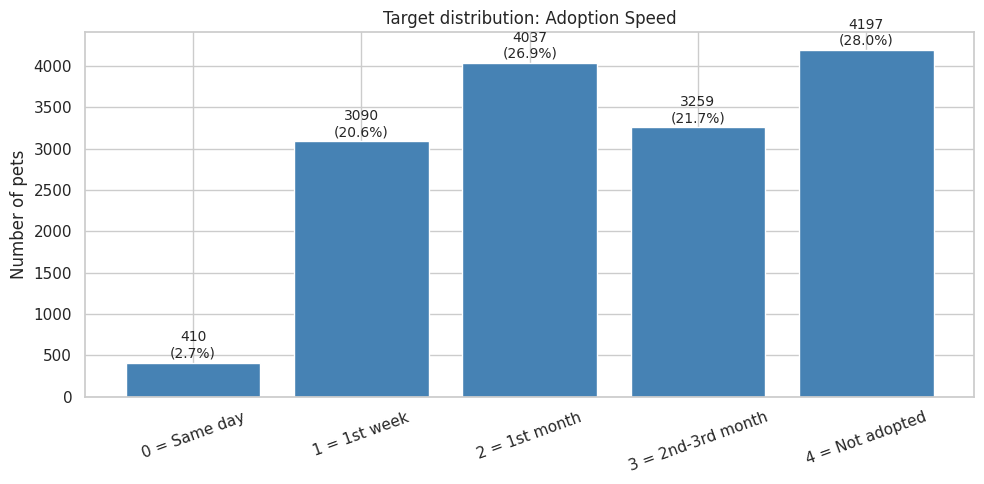

In [7]:
# Distribution of the target column
speed_labels = {0: '0 = Same day', 1: '1 = 1st week', 2: '2 = 1st month',
                3: '3 = 2nd-3rd month', 4: '4 = Not adopted'}

counts = train['AdoptionSpeed'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
bars = plt.bar([speed_labels[i] for i in counts.index], counts.values, color='steelblue')
# Write the count + percentage above every bar
for bar, c in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, c + 60,
             f'{c}\n({c / len(train) * 100:.1f}%)', ha='center', fontsize=10)
plt.title('Target distribution: Adoption Speed')
plt.ylabel('Number of pets')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

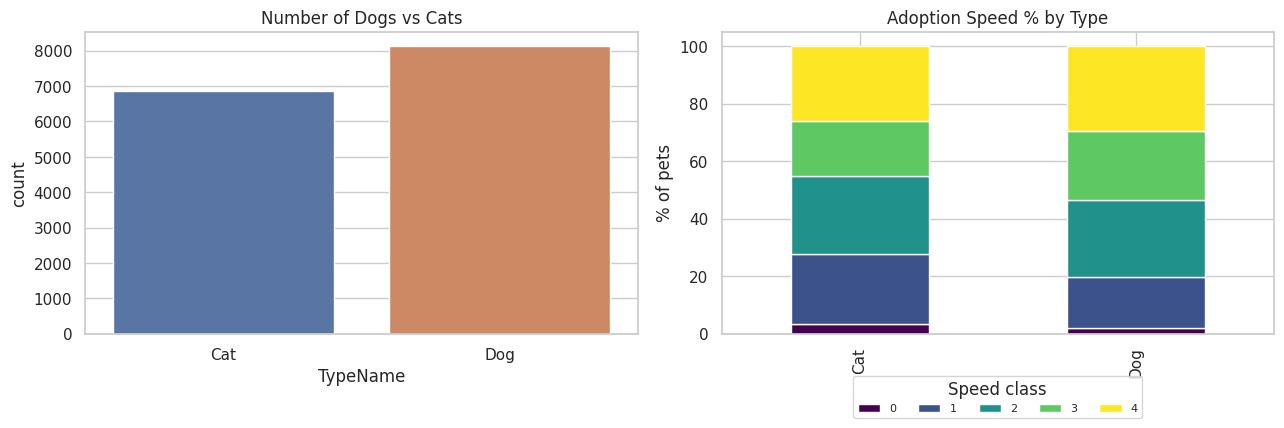

In [8]:
# Dogs vs Cats: how many, and how fast are they adopted?
type_map = {1: 'Dog', 2: 'Cat'}
df_type = df.copy()
df_type['TypeName'] = df_type['Type'].map(type_map)

plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
sns.countplot(data=df_type, x='TypeName', hue='TypeName',
              palette=['#4C72B0', '#DD8452'], legend=False)
plt.title('Number of Dogs vs Cats')

plt.subplot(1, 2, 2)
# Percentage of each adoption speed inside each type
ct = pd.crosstab(df_type['TypeName'], df_type['AdoptionSpeed'], normalize='index') * 100
ct.columns = [f'{c}' for c in ct.columns]
ct.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='viridis')
plt.title('Adoption Speed % by Type')
plt.ylabel('% of pets')
plt.xlabel('')
plt.legend(title='Speed class', fontsize=8, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

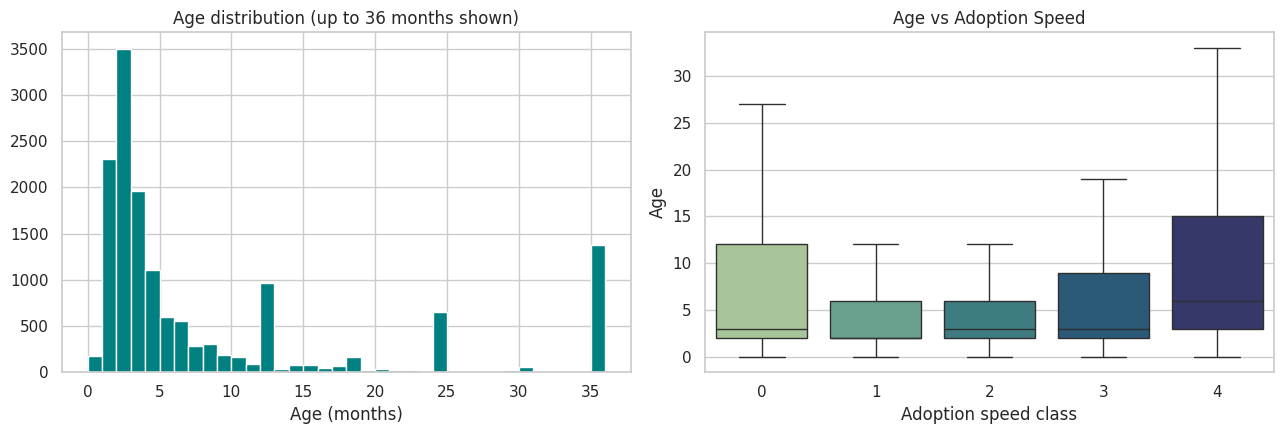

In [9]:
# Age: distribution + relation with adoption speed
# (Age is in months, 0 = less than 1 month)
plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
df['Age'].clip(upper=36).hist(bins=36, color='teal')
plt.title('Age distribution (up to 36 months shown)')
plt.xlabel('Age (months)')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='AdoptionSpeed', y='Age', hue='AdoptionSpeed',
            palette='crest', showfliers=False, legend=False)
plt.title('Age vs Adoption Speed')
plt.xlabel('Adoption speed class')

plt.tight_layout()
plt.show()

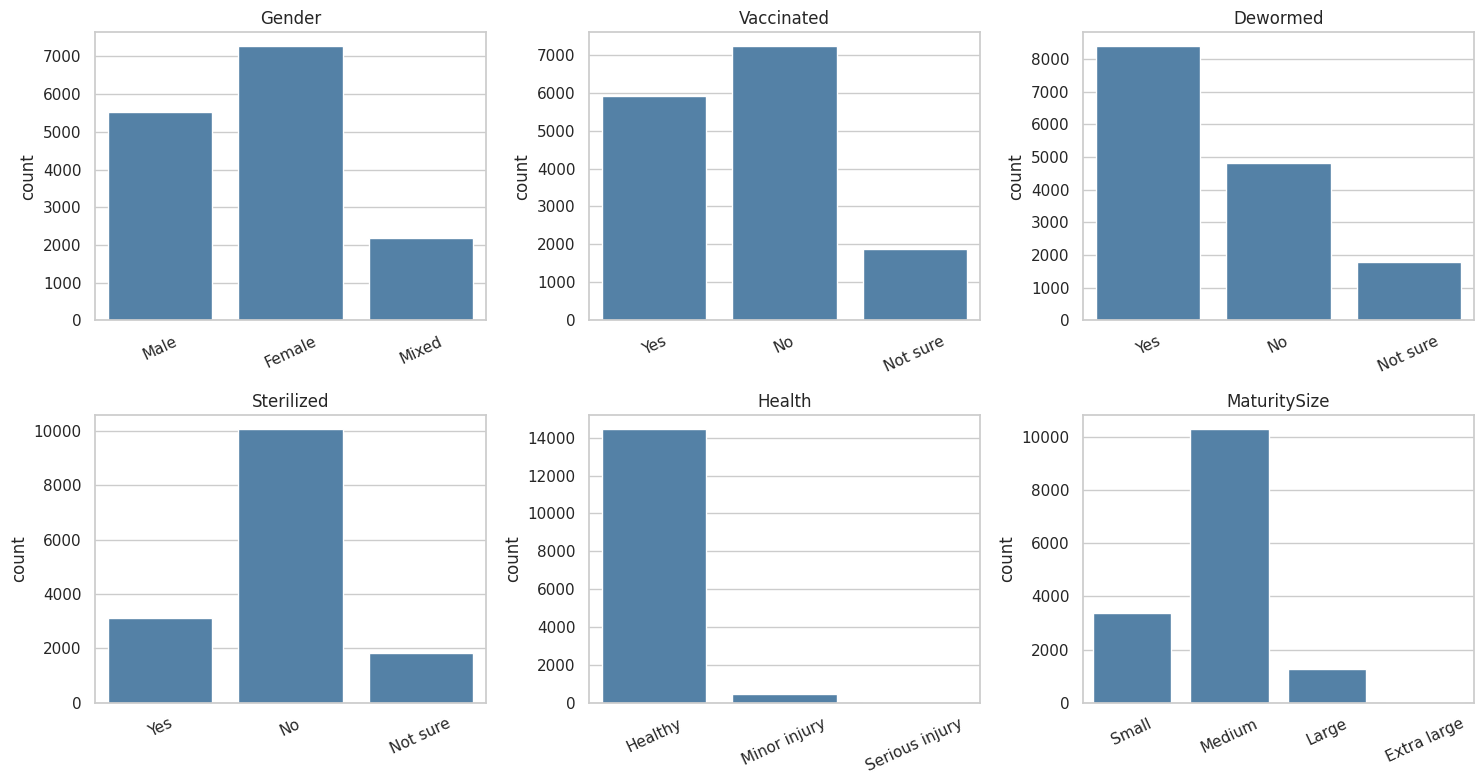

In [10]:
# Count plots for the important categorical columns
cat_info = [
    ('Gender',       {1: 'Male', 2: 'Female', 3: 'Mixed'}),
    ('Vaccinated',   {1: 'Yes', 2: 'No', 3: 'Not sure'}),
    ('Dewormed',     {1: 'Yes', 2: 'No', 3: 'Not sure'}),
    ('Sterilized',   {1: 'Yes', 2: 'No', 3: 'Not sure'}),
    ('Health',       {1: 'Healthy', 2: 'Minor injury', 3: 'Serious injury'}),
    ('MaturitySize', {1: 'Small', 2: 'Medium', 3: 'Large', 4: 'Extra large'}),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, mapping) in zip(axes.flat, cat_info):
    mapped = df[col].map(mapping)
    sns.countplot(x=mapped, ax=ax, color='steelblue', order=list(mapping.values()))
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

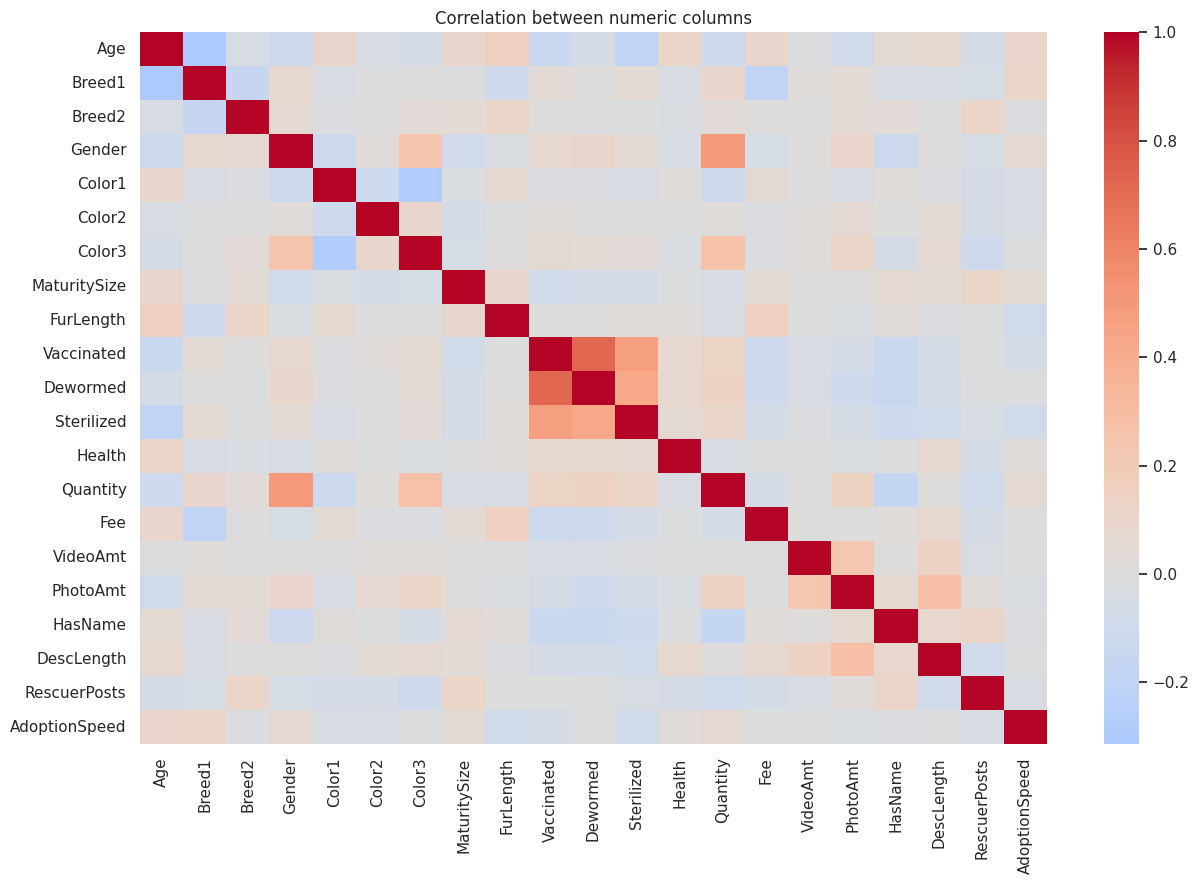

In [11]:
# Correlation between the numeric columns (before one-hot encoding)
num_cols = ['Age', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3',
            'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed', 'Sterilized',
            'Health', 'Quantity', 'Fee', 'VideoAmt', 'PhotoAmt',
            'HasName', 'DescLength', 'RescuerPosts', 'AdoptionSpeed']

plt.figure(figsize=(13, 9))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm', center=0)
plt.title('Correlation between numeric columns')
plt.tight_layout()
plt.show()

**What we noticed from the EDA:**
- The data is **imbalanced**: most pets are in classes 1, 2, 4, while class 0 (same-day adoption) is very small (~3%).
- The biggest class is **4 = Not adopted** (~28%) - so this is a hard problem.
- **Younger pets** seem to get adopted faster (the boxplot shows lower age for classes 0-2).
- Most pets are healthy, vaccinated status varies a lot, and most listings have a small quantity (1-2 pets).

## 4. Preprocessing

Steps:
1. Separate features `X` and target `y`
2. Turn the categorical codes into **one-hot** columns (0/1)
3. Split the data: **80% train / 20% test**
4. Scale the numbers with `StandardScaler`

In [12]:
# Separate features (X) and target (y)
X = df.drop(columns=['AdoptionSpeed'])
y = df['AdoptionSpeed']

# One-hot encoding: every category becomes its own 0/1 column
cat_cols = ['Type', 'Gender', 'Color1', 'Color2', 'Color3', 'MaturitySize',
            'FurLength', 'Vaccinated', 'Dewormed', 'Sterilized', 'Health', 'State']
X = pd.get_dummies(X, columns=cat_cols)

# Note: Breed1 / Breed2 have ~300 possible codes -> too many for one-hot.
# We keep them as numbers; tree models can handle them fine.

print('Final feature matrix shape:', X.shape)

Final feature matrix shape: (14993, 68)


In [13]:
# Split the data: 80% for training, 20% for testing
# stratify=y keeps the same class balance in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features so they are all on a similar scale.
# This is important for Logistic Regression. Tree models don't care, but it doesn't hurt.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn the scaling from train only
X_test_scaled = scaler.transform(X_test)         # apply the same scaling to test

print('X_train:', X_train_scaled.shape, '| X_test:', X_test_scaled.shape)
print()
print('Class balance in train (%):')
print((y_train.value_counts(normalize=True).sort_index() * 100).round(1))

X_train: (11994, 68) | X_test: (2999, 68)

Class balance in train (%):
AdoptionSpeed
0     2.7
1    20.6
2    26.9
3    21.7
4    28.0
Name: proportion, dtype: float64


## 5. Train the models

We train 3 classic classification models:
- **Logistic Regression** - a simple linear model, fast and a good baseline
- **Decision Tree** - one big tree of if/else questions (can overfit easily)
- **Random Forest** - many decision trees combined, usually the most accurate

In [14]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

results = []
predictions = {}
fitted = {}          # we keep the trained models here for later use

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    fitted[name] = model
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    predictions[name] = test_pred
    results.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, train_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Macro F1 (test)': f1_score(y_test, test_pred, average='macro'),
    })
    print(name, '-> trained.')

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df

Logistic Regression -> trained.


Decision Tree -> trained.


Random Forest -> trained.


,Train Accuracy,Test Accuracy,Macro F1 (test)
Model,,,
Logistic Regression,0.395,0.378,0.286
Decision Tree,0.998,0.350,0.307
Random Forest,0.998,0.433,0.366


## 6. Compare the models and choose the best one

We compare the models on the **test set** (data the models never saw):
- **Test Accuracy** - % of correct predictions
- **Macro F1** - a fairer score when the classes are imbalanced (our case)
- **Train vs Test gap** - if train is much higher than test, the model is overfitting

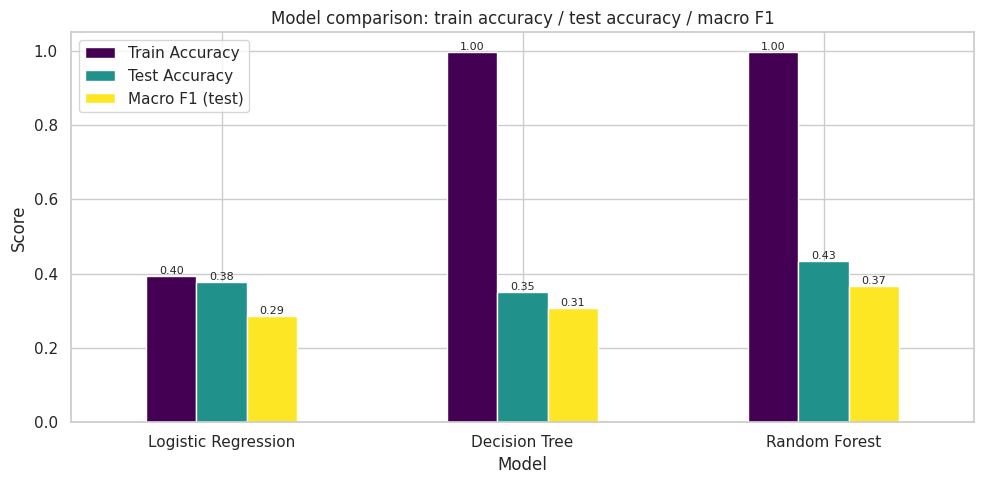

In [15]:
# Visual comparison of the three models
ax = results_df.plot(kind='bar', figsize=(10, 5), rot=0, colormap='viridis')
plt.title('Model comparison: train accuracy / test accuracy / macro F1')
plt.ylabel('Score')
plt.ylim(0, 1.05)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8)
plt.tight_layout()
plt.show()

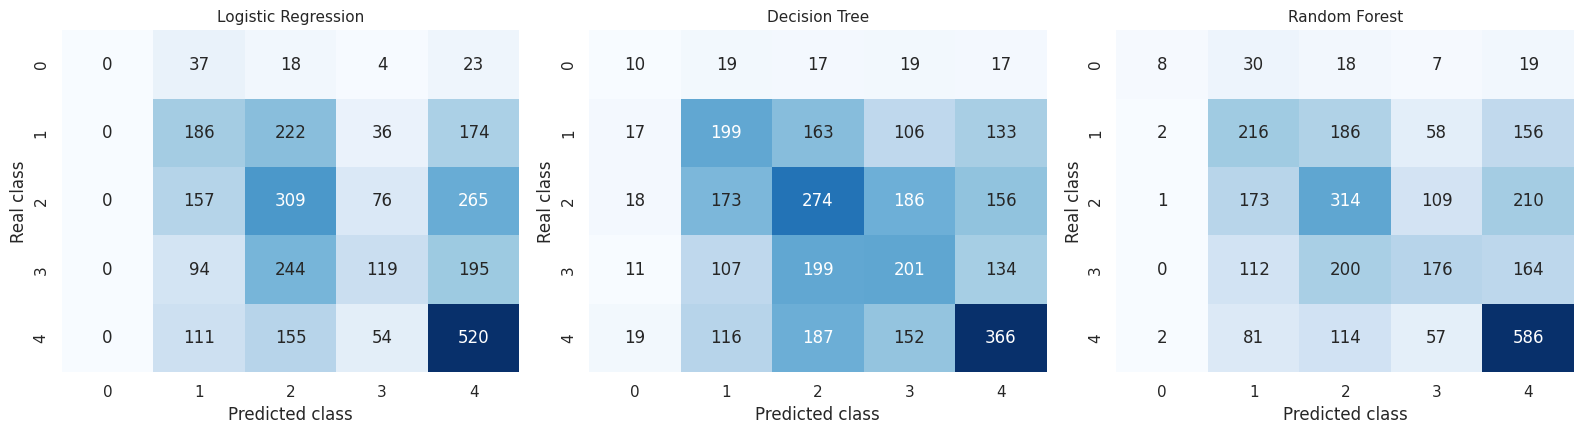

In [16]:
# Confusion matrix for each model
# rows = real class, columns = predicted class, the diagonal = correct predictions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, preds) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Real class')
plt.tight_layout()
plt.show()

In [17]:
# Detailed report for each model: precision / recall / f1 for every class
for name, preds in predictions.items():
    print('=' * 55)
    print(name)
    print('=' * 55)
    print(classification_report(y_test, preds, digits=3))

Logistic Regression
              precision    recall  f1-score   support

           0      0.000     0.000     0.000        82
           1      0.318     0.301     0.309       618
           2      0.326     0.383     0.352       807
           3      0.412     0.183     0.253       652
           4      0.442     0.619     0.516       840

    accuracy                          0.378      2999
   macro avg      0.299     0.297     0.286      2999
weighted avg      0.366     0.378     0.358      2999

Decision Tree
              precision    recall  f1-score   support

           0      0.133     0.122     0.127        82
           1      0.324     0.322     0.323       618
           2      0.326     0.340     0.333       807
           3      0.303     0.308     0.305       652
           4      0.454     0.436     0.445       840

    accuracy                          0.350      2999
   macro avg      0.308     0.305     0.307      2999
weighted avg      0.351     0.350     0.351

/home/z/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/z/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/z/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [18]:
# Choose the best model: highest Test Accuracy, Macro F1 as a tie-breaker
best_model_name = results_df.sort_values(
    ['Test Accuracy', 'Macro F1 (test)'], ascending=False).index[0]

print('>>> BEST MODEL:', best_model_name)
results_df

>>> BEST MODEL: Random Forest


,Train Accuracy,Test Accuracy,Macro F1 (test)
Model,,,
Logistic Regression,0.395,0.378,0.286
Decision Tree,0.998,0.350,0.307
Random Forest,0.998,0.433,0.366


## 7. Interpret the results - what drives adoption speed?

Accuracy numbers are not enough - we want to understand **why** the model decides.
For the Random Forest we can look at the **feature importance**: a score (0 to 1) that shows how much each feature helped the trees make decisions.

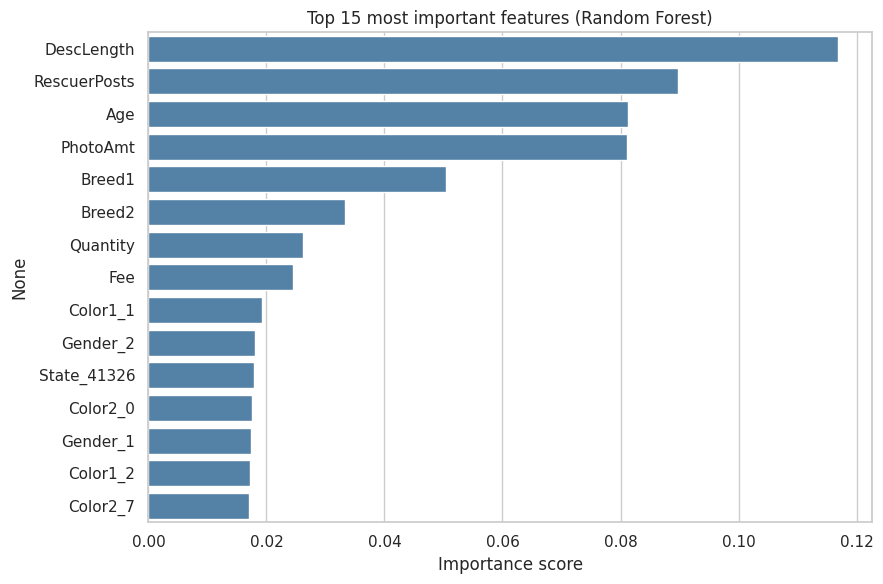

Top 5 features:
1. DescLength: 0.117
2. RescuerPosts: 0.090
3. Age: 0.081
4. PhotoAmt: 0.081
5. Breed1: 0.050


In [19]:
# Feature importance from the Random Forest (the best model)
rf = fitted['Random Forest']
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

top15 = importances.head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=top15.values, y=top15.index, color='steelblue')
plt.title('Top 15 most important features (Random Forest)')
plt.xlabel('Importance score')
plt.tight_layout()
plt.show()

print('Top 5 features:')
for i, (feat, score) in enumerate(importances.head(5).items(), 1):
    print(f'{i}. {feat}: {score:.3f}')

**How to read this chart:**
- **DescLength** (description length) is the strongest signal - a longer, more informative description gives the adopter more confidence to decide.
- **RescuerPosts** comes second - rescuers who post many pets behave differently from one-time posters.
- **Age** and **PhotoAmt** are next: younger pets get adopted faster (the boxplot in the EDA showed the same thing), and more photos = a nicer profile.
- The one-hot dummy columns have small individual importance, which is normal because their information is split over many columns.

**Limitations of this model:**
1. We used only the profile features - the pet photos, the text meaning (NLP) and the metadata/sentiment files could add a lot.
2. The classes are imbalanced (class 0 is tiny), which pushes accuracy down for rare classes.
3. With 5 hard-to-separate classes, ~43% accuracy is a solid result using tabular data only.

## 8. Conclusion

- The best model is the **Random Forest**: it gives the highest test accuracy (~43%) and the best Macro F1 (~0.37) on the test set.
- The **Decision Tree** overfits: it scores ~100% on train but much lower on test. The **Random Forest** fixes this by combining many trees.
- **Logistic Regression** is simple and honest, but linear models are weaker here because many features are codes, not real numbers.
- The most important factors for adoption speed are the **description length**, the **rescuer's experience**, the pet's **age** and the **number of photos**.
- With 5 classes and imbalanced data, this accuracy is a realistic result for this dataset using only the profile features.
- A simple **Streamlit web app** was built on top of this notebook for deployment (Step 6 of the project): page 1 explores the data, page 2 lets the user enter a pet profile and get a prediction.

**Ideas to improve the score (future work):**
1. Extract more features from the description text (sentiment, keywords).
2. Use the pet photos (image features) and the provided metadata / sentiment files.
3. Hyperparameter tuning (e.g., `GridSearchCV`) or trying boosting models (XGBoost / LightGBM).
4. The Kaggle competition uses Quadratic Weighted Kappa as its metric - we could optimize it directly.